In [5]:
import argparse
import os
import time
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn

    

import torchvision
import torchvision.transforms as transforms

from models import *   # bring everything in the folder models

global best_prec
use_gpu = torch.cuda.is_available()
print('=> Building model...')
    
    
batch_size = 128

model_name = "cifar10"
#model = cifar10()
# model = VGG19()
model = resnet20_cifar()

        

normalize = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.247, 0.243, 0.262])


train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        normalize,
    ]))
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)


test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        normalize,
    ]))

testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)


print_freq = 100 # every 100 batches, accuracy printed. Here, each batch includes "batch_size" data points
# CIFAR10 has 50,000 training data, and 10,000 validation data.

def train(trainloader, model, criterion, optimizer, epoch):
    batch_time = AverageMeter()   ## at the begining of each epoch, this should be reset
    data_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    model.train()

    end = time.time()  # measure current time
    
    for i, (input, target) in enumerate(trainloader):
        # measure data loading time
        data_time.update(time.time() - end)  # data loading time

        input, target = input.cuda(), target.cuda()

        # compute output
        output = model(input)
        loss = criterion(output, target)

        # measure accuracy and record loss
        prec = accuracy(output, target)[0]
        losses.update(loss.item(), input.size(0))
        top1.update(prec.item(), input.size(0))

        # compute gradient and do SGD step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # measure elapsed time
        batch_time.update(time.time() - end) # time spent to process one batch
        end = time.time()


        if i % print_freq == 0:
            print('Epoch: [{0}][{1}/{2}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Data {data_time.val:.3f} ({data_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   epoch, i, len(trainloader), batch_time=batch_time,
                   data_time=data_time, loss=losses, top1=top1))

            

def validate(val_loader, model, criterion ):
    batch_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    # switch to evaluate mode
    model.eval()

    end = time.time()
    with torch.no_grad():
        for i, (input, target) in enumerate(val_loader):
         
            input, target = input.cuda(), target.cuda()

            # compute output
            output = model(input)
            loss = criterion(output, target)

            # measure accuracy and record loss
            prec = accuracy(output, target)[0]
            losses.update(loss.item(), input.size(0))
            top1.update(prec.item(), input.size(0))

            # measure elapsed time
            batch_time.update(time.time() - end)
            end = time.time()

            if i % print_freq == 0:  # This line shows how frequently print out the status. e.g., i%5 => every 5 batch, prints out
                print('Test: [{0}/{1}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   i, len(val_loader), batch_time=batch_time, loss=losses,
                   top1=top1))

    print(' * Prec {top1.avg:.3f}% '.format(top1=top1))
    return top1.avg


def accuracy(output, target, topk=(1,5)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk) # 5
    batch_size = target.size(0) # 128

    _, pred = output.topk(maxk, 1, True, True) # topk(k, dim=None, largest=True, sorted=True)
                                    # will output (max value, its index)
    pred = pred.t()               # transpose
    correct = pred.eq(target.view(1, -1).expand_as(pred))   # "-1": calculate automatically

    res = []
    for k in topk: # 1, 5
        correct_k = correct[:k].view(-1).float().sum(0)  # view(-1): make a flattened 1D tensor
        res.append(correct_k.mul_(100.0 / batch_size))   # correct: size of [maxk, batch_size]
    return res


class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n    ## n is impact factor
        self.count += n
        self.avg = self.sum / self.count

        
def save_checkpoint(state, is_best, fdir):
    filepath = os.path.join(fdir, 'checkpoint.pth')
    torch.save(state, filepath)
    if is_best:
        shutil.copyfile(filepath, os.path.join(fdir, 'model_best.pth.tar'))


def adjust_learning_rate(optimizer, epoch):
    """For resnet, the lr starts from 0.1, and is divided by 10 at 80 and 120 epochs"""
    adjust_list = [150, 225]
    if epoch in adjust_list:
        for param_group in optimizer.param_groups:
            param_group['lr'] = param_group['lr'] * 0.1        

#model = nn.DataParallel(model).cuda()
#all_params = checkpoint['state_dict']
#model.load_state_dict(all_params, strict=False)
#criterion = nn.CrossEntropyLoss().cuda()
#validate(testloader, model, criterion)

=> Building model...
Files already downloaded and verified
Files already downloaded and verified


In [6]:
def accuracy(output, target, topk=(1,5)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk) # 5
    batch_size = target.size(0) # 128

    _, pred = output.topk(maxk, 1, True, True) # topk(k, dim=None, largest=True, sorted=True)
                                    # will output (max value, its index)
    pred = pred.t()               # transpose
    correct = pred.eq(target.view(1, -1).expand_as(pred))   # "-1": calculate automatically

    res = []
    for k in topk: # 1, 5
        correct_k = correct[:k].reshape(-1).float().sum(0)  # view(-1): make a flattened 1D tensor
        res.append(correct_k.mul_(100.0 / batch_size))   # correct: size of [maxk, batch_size]
    return res

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49392712..1.5658436].


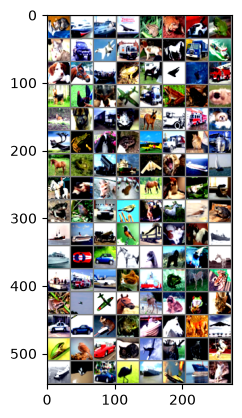

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# get some random training images
dataiter = iter(testloader)
images, labels = next(dataiter) ## If you run this line, the next data batch is called subsequently.

# show images
imshow(torchvision.utils.make_grid(images))


In [7]:
model = resnet20_cifar()


# This cell is from the website

lr = 0.1



weight_decay = 5e-4
epochs = 60
best_prec = 0

model = model.cuda()
criterion = nn.CrossEntropyLoss().cuda()
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30, 45], gamma=0.1)

# weight decay: for regularization to prevent overfitting


if not os.path.exists('result'):
    os.makedirs('result')
    
fdir = 'result/'+str(model_name)

if not os.path.exists(fdir):
    os.makedirs(fdir)
        

for epoch in range(0, epochs):
    adjust_learning_rate(optimizer, epoch)

    train(trainloader, model, criterion, optimizer, epoch)
    
    # evaluate on test set
    print("Validation starts")
    prec = validate(testloader, model, criterion)

    scheduler.step()

    # remember best precision and save checkpoint
    is_best = prec > best_prec
    best_prec = max(prec,best_prec)
    print('best acc: {:1f}'.format(best_prec))
    save_checkpoint({
        'epoch': epoch + 1,
        'state_dict': model.state_dict(),
        'best_prec': best_prec,
        'optimizer': optimizer.state_dict(),
    }, is_best, fdir)
    

Epoch: [0][0/391]	Time 22.424 (22.424)	Data 20.061 (20.061)	Loss 2.6154 (2.6154)	Prec 8.594% (8.594%)
Epoch: [0][100/391]	Time 0.047 (0.262)	Data 0.018 (0.210)	Loss 1.7536 (1.9380)	Prec 37.500% (26.238%)
Epoch: [0][200/391]	Time 0.032 (0.151)	Data 0.007 (0.111)	Loss 1.5011 (1.7972)	Prec 45.312% (31.794%)
Epoch: [0][300/391]	Time 0.031 (0.114)	Data 0.005 (0.078)	Loss 1.4348 (1.6928)	Prec 46.875% (36.145%)
Validation starts
Test: [0/79]	Time 21.208 (21.208)	Loss 1.6325 (1.6325)	Prec 45.312% (45.312%)
 * Prec 42.780% 
best acc: 42.780000
Epoch: [1][0/391]	Time 18.096 (18.096)	Data 17.998 (17.998)	Loss 1.4057 (1.4057)	Prec 49.219% (49.219%)
Epoch: [1][100/391]	Time 0.026 (0.218)	Data 0.007 (0.187)	Loss 1.1730 (1.1826)	Prec 56.250% (57.882%)
Epoch: [1][200/391]	Time 0.046 (0.133)	Data 0.002 (0.101)	Loss 1.0463 (1.1505)	Prec 57.031% (58.310%)
Epoch: [1][300/391]	Time 0.053 (0.110)	Data 0.002 (0.074)	Loss 0.9042 (1.1152)	Prec 71.094% (59.627%)
Validation starts
Test: [0/79]	Time 15.428 (15.42

In [8]:

fdir = 'result/'+str(model_name)+'/model_best.pth.tar'

checkpoint = torch.load(fdir)
model.load_state_dict(checkpoint['state_dict'])


criterion = nn.CrossEntropyLoss().cuda()

model.eval()
model.cuda()


prec = validate(testloader, model, criterion)


C:\tmp\ipykernel_46752\1254959102.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(fdir)


Test: [0/79]	Time 56.237 (56.237)	Loss 0.2143 (0.2143)	Prec 92.188% (92.188%)
 * Prec 91.150% 


In [ ]:
# HW

#  1. train resnet20 and vgg16 to achieve >90% accuracy 
#  2. save your trained model in the result folder 
#  3. Restart your jupyter notebook by "Kernel - Restart & Clear Output"
#  4. Load your saved model for vgg16 and validate to see the accuracy
#  5. such as the last part of "[W2S2_example2]_CNN_for_MNIST.ipynb", prehook the input layers of all the conv layers.
#  6. from the first prehooked input, compute to get the second prehooked input. 
#  7. Compare your computed second input vs. the prehooked second input.


In [ ]:
m = model.conv1

In [ ]:
(r(m(pre0) + pre0) - prec1).abs().sum()

In [9]:
def quantize(weight, alpha, bits):
    # similar to code 8 uniform_quantization function
    w_bits = bits - 1       # -1 cause we exclude sign bit
    w_div = weight.div(alpha)
    w_clip = w_div.clip(-1, 1)
    w_sign = w_clip.sign()
    w_abs = w_clip.abs()
    w_int = w_abs.mul(2 ** w_bits - 1).round()
    w_quant = w_int.div(2 ** w_bits - 1).mul(w_sign).mul(alpha)
    return w_quant

In [14]:
# Stuff for HW4 Q1.1
# Note: Max weight is 1.0625, min weight is -0.7379
# Used alpha = 1.1 
# Quantize to 4 bit weights

import copy

model_cp = copy.deepcopy(model)

for layer in model_cp.modules():
    if isinstance(layer, torch.nn.Conv2d):
        # Apply quantization function to layer.weight
        layer.weight.data = quantize(layer.weight, alpha=0.4, bits=4)


In [15]:
# Evaluate accuracy from 4-bit quantized model (Q1.1)

criterion = nn.CrossEntropyLoss().cuda()

model_cp.eval()
model_cp.cuda()

prec = validate(testloader, model_cp, criterion)

Test: [0/79]	Time 20.756 (20.756)	Loss 0.5593 (0.5593)	Prec 78.125% (78.125%)
 * Prec 81.120% 


In [16]:
# Using the weight_quantize_fn() from [Code8]
import argparse
import os
import time
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn
   

import torchvision
import torchvision.transforms as transforms

from models import *



def act_quantization(b):

    def uniform_quant(x, b=3):
        xdiv = x.mul(2 ** b - 1)
        xhard = xdiv.round().div(2 ** b - 1)
        return xhard

    class uq(torch.autograd.Function):   # here single underscore means this class is for internal use

        def forward(ctx, input, alpha):
            input_d = input/alpha
            input_c = input_d.clamp(max=1)  # Mingu edited for Alexnet
            input_q = uniform_quant(input_c, b)
            ctx.save_for_backward(input, input_q)
            input_q_out = input_q.mul(alpha)
            return input_q_out

    return uq().apply




def weight_quantization(b):

    def uniform_quant(x, b):
        xdiv = x.mul((2 ** b - 1))
        xhard = xdiv.round().div(2 ** b - 1)  
        return xhard

    class uq(torch.autograd.Function):

        def forward(ctx, input, alpha):
            input_d = input/alpha                          # weights are first divided by alpha                       
            input_c = input_d.clamp(min=-1, max=1)       # then clipped to [-1,1]
            sign = input_c.sign()
            input_abs = input_c.abs()
            input_q = uniform_quant(input_abs, b).mul(sign)
            ctx.save_for_backward(input, input_q)
            input_q_out = input_q.mul(alpha)               # rescale to the original range
            return input_q_out

    return uq().apply



class weight_quantize_fn(nn.Module):
    def __init__(self, w_bit):
        super(weight_quantize_fn, self).__init__()
        self.w_bit = w_bit-1
        self.weight_q = weight_quantization(b=self.w_bit)
        self.wgt_alpha = 0.4 # Changed alpha value to 0.4

    def forward(self, weight):
        weight_q = self.weight_q(weight, self.wgt_alpha)
        
        return weight_q
    
    

In [17]:
# HW4 Q1.2
model_cp2 = copy.deepcopy(model)
wqfn = weight_quantize_fn(w_bit=4)

for layer in model_cp2.modules():
    if isinstance(layer, torch.nn.Conv2d):
        # Apply quantization function to layer.weight
        weights_q = wqfn.forward(layer.weight)
        layer.weight.data = weights_q

C:\tmp\ipykernel_46752\3725216763.py:62: DeprecationWarning: <class '__main__.weight_quantization.<locals>.uq'> should not be instantiated. Methods on autograd functionsare all static, so you should invoke them on the class itself. Instantiating an autograd function will raise an error in a future version of PyTorch.
  return uq().apply


In [18]:
# Evaluate 4-bit quantized model for Q1.2

criterion = nn.CrossEntropyLoss().cuda()

model_cp2.eval()
model_cp2.cuda()

prec = validate(testloader, model_cp2, criterion)

Test: [0/79]	Time 24.360 (24.360)	Loss 0.5593 (0.5593)	Prec 78.125% (78.125%)
 * Prec 81.120% 


In [19]:
# HW4 Q1.3 (8-bit quantization)
model_cp3 = copy.deepcopy(model)
wqfn = weight_quantize_fn(w_bit=8)

for layer in model_cp3.modules():
    if isinstance(layer, torch.nn.Conv2d):
        # Apply quantization function to layer.weight
        weights_q = wqfn.forward(layer.weight)
        layer.weight.data = weights_q

C:\tmp\ipykernel_46752\3725216763.py:62: DeprecationWarning: <class '__main__.weight_quantization.<locals>.uq'> should not be instantiated. Methods on autograd functionsare all static, so you should invoke them on the class itself. Instantiating an autograd function will raise an error in a future version of PyTorch.
  return uq().apply


In [20]:
# Evaluate 8-bit quantized model for Q1.3

criterion = nn.CrossEntropyLoss().cuda()

model_cp3.eval()
model_cp3.cuda()

prec = validate(testloader, model_cp3, criterion)

Test: [0/79]	Time 18.628 (18.628)	Loss 0.3159 (0.3159)	Prec 91.406% (91.406%)
 * Prec 89.210% 
